# The Limber approximation, visually

When we observe the sky we see 3D structure **projected** onto a 2D sphere. The angular power spectrum $C_\ell$ of a projected field is an integral over the 3D power spectrum $P(k)$. Written out exactly, it contains spherical Bessel functions $j_\ell(k\chi)$, which oscillate quickly, so the integral is **slow and painful to converge** numerically. The **Limber approximation** (Limber 1953; Kaiser 1992) replaces it with a single, smooth, one-dimensional integral. Almost every weak-lensing and photometric-clustering analysis uses it.

This notebook:

1. writes down the exact projection integral and shows what its integrand looks like,
2. shows *why* it converges slowly, and why that same structure is what makes Limber work,
3. compares the exact $C_\ell$ with the Limber result for a **broad** and a **narrow** redshift distribution,
4. carries the comparison into real space, $w(\theta)$, as Simon (2007) does.

Main reading: Simon (2007), arXiv:[astro-ph/0609165](https://arxiv.org/abs/astro-ph/0609165), and Lemos, Challinor & Efstathiou (2017), arXiv:[1704.01054](https://arxiv.org/abs/1704.01054). The full reference list is at the end.

Everything here is computed from scratch with `numpy`/`scipy`: a linear Eisenstein & Hu (1998) no-wiggle power spectrum in a flat ΛCDM cosmology. No `CAMB` or `CCL` needed.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import spherical_jn, eval_legendre
from scipy.integrate import quad, cumulative_trapezoid
from scipy.interpolate import interp1d

# A small, consistent plotting style (categorical colours in fixed order)
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED = "#0b0b0b", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. The exact projection integral

Take a 3D field $\delta(\mathbf{x}, z)$ (here the galaxy overdensity, with linear bias $b=1$) and project it with a normalised radial weight $W(\chi)$, where $\chi$ is comoving distance and $\int W\,d\chi = 1$:

$$
\delta_{2D}(\hat{\mathbf n}) = \int_0^{\infty} d\chi\; W(\chi)\,\delta\big(\chi\hat{\mathbf n},\, z(\chi)\big),
\qquad W(\chi) = n(z)\,\frac{dz}{d\chi}.
$$

Expand $\delta$ in Fourier modes and use the plane-wave (Rayleigh) expansion
$e^{i\mathbf k\cdot\mathbf x} = 4\pi\sum_{\ell m} i^\ell j_\ell(kx)\,Y^*_{\ell m}(\hat{\mathbf k})\,Y_{\ell m}(\hat{\mathbf x})$.
With linear growth, $P(k,z) = D^2(z)\,P(k)$, the angular power spectrum is

$$
\boxed{\;C_\ell = \frac{2}{\pi}\int_0^\infty dk\,k^2\,P(k)\;\big[I_\ell(k)\big]^2,
\qquad
I_\ell(k) = \int_0^\infty d\chi\;W(\chi)\,D(\chi)\;j_\ell(k\chi)\;}
\tag{1}
$$

This is the same structure as Eqs. (6a,b) of Lemos et al. (2017), who write it for the lensing potential. It is a **double integral with an oscillating kernel**:

* $j_\ell(x)$ is essentially zero for $x \lesssim \nu \equiv \ell + \tfrac12$. It peaks near $x \approx \nu$ (with width $\sim\nu^{1/3}$) and then oscillates with period $2\pi$ while decaying as $1/x$.
* To compute $I_\ell(k)$ you must resolve oscillations of period $2\pi/k$ in $\chi$. Then the outer $k$ integral has to resolve the oscillations of $I_\ell(k)$ itself, with period $\sim 2\pi/\bar\chi$.
* The amount of work grows with $\ell$.

Lemos et al. call the exact expressions *"time consuming to evaluate accurately at high multipoles due to the rapid oscillations of the spherical Bessel functions."*

## 2. The Limber approximation

If everything else in the integrand varies slowly compared with $j_\ell$, then $j_\ell$ acts like a delta function:

$$
j_\ell(k\chi) \;\to\; \sqrt{\frac{\pi}{2\nu}}\;\delta_D(\nu - k\chi), \qquad \nu = \ell + \tfrac12
\tag{2}
$$

(Lemos et al. 2017, Eq. 12; LoVerde & Afshordi 2008). Equivalently, we can use the closure relation
$\int_0^\infty dk\,k^2\,j_\ell(k\chi)\,j_\ell(k\chi') = \frac{\pi}{2\chi^2}\,\delta_D(\chi-\chi')$.
Inserting (2) into (1) gives

$$
I_\ell(k) \approx \sqrt{\frac{\pi}{2\nu}}\;\frac{W(\nu/k)\,D(\nu/k)}{k},
\qquad\Longrightarrow\qquad
\boxed{\;C_\ell^{\rm Limber} = \int_0^\infty d\chi\;\frac{W^2(\chi)}{\chi^2}\;P\!\left(k=\frac{\ell+1/2}{\chi},\, z(\chi)\right)\;}
\tag{3}
$$

This is a single integral of a smooth, positive function. Each multipole $\ell$ at distance $\chi$ probes just one wavenumber, $k = \nu/\chi$.

**Which $\nu$?** Older papers use $k=\ell/\chi$. LoVerde & Afshordi (2008) show that $\nu=\ell+\frac12$ makes the leading correction $\mathcal O(\nu^{-2})$ rather than $\mathcal O(\ell^{-1})$. Lemos et al. (2017, footnote 4) point out that published analyses have mixed the two conventions. We will plot both.

**When should it fail?** When $W(\chi)$ is *not* slowly varying, i.e. for narrow redshift distributions, and at low $\ell$. Simon (2007) makes this sharp: for a top-hat of width $\Delta r$ the Limber amplitude scales as $1/\Delta r$ and **diverges** for thin shells (his Eq. 19). The exact answer instead tends to the finite 3D correlation function, $w(\theta)\to\xi(r\theta)$.

## 3. A look at the spherical Bessel functions

The $j_\ell(x)$ come from the Rayleigh plane-wave expansion above. Take a plane wave $e^{i\mathbf k\cdot\mathbf x}$ and look at it only on a sphere of radius $\chi$ around the observer: you get a pattern on the sky that can be expanded in spherical harmonics. $j_\ell(k\chi)$ is the amount of multipole $\ell$ in that pattern. They are related to the ordinary Bessel functions by $j_\ell(x) = \sqrt{\pi/2x}\,J_{\ell+1/2}(x)$, and the first few are elementary:

$$
j_0(x) = \frac{\sin x}{x},\qquad
j_1(x) = \frac{\sin x}{x^2} - \frac{\cos x}{x},\qquad
j_2(x) = \left(\frac{3}{x^2} - 1\right)\frac{\sin x}{x} - \frac{3\cos x}{x^2}.
$$

Two limits are worth remembering:

$$
j_\ell(x) \simeq \frac{x^\ell}{(2\ell+1)!!}\quad (x \ll \ell),
\qquad\qquad
j_\ell(x) \simeq \frac{\sin(x - \ell\pi/2)}{x}\quad (x \gg \ell).
$$

So $j_\ell$ is suppressed as $x^\ell$ at small argument. For large $\ell$ it is essentially zero until $x \approx \nu = \ell + \frac12$. It has a first, broad peak there, of width $\sim\nu^{1/3}$, and then oscillates with period $2\pi$ and amplitude $\sim1/x$.

There is a simple geometric reason for the switch-on. A wave of wavelength $2\pi/k$ laid across a sphere of radius $\chi$ cannot make angular structure finer than about $1/(k\chi)$ radians, so it can only feed multipoles $\ell \lesssim k\chi$. That is why $j_\ell(k\chi)\approx0$ for $k\chi<\ell$. It is also the origin of the one-to-one link between multipole and wavenumber, $k\approx\nu/\chi$, at the heart of Limber.

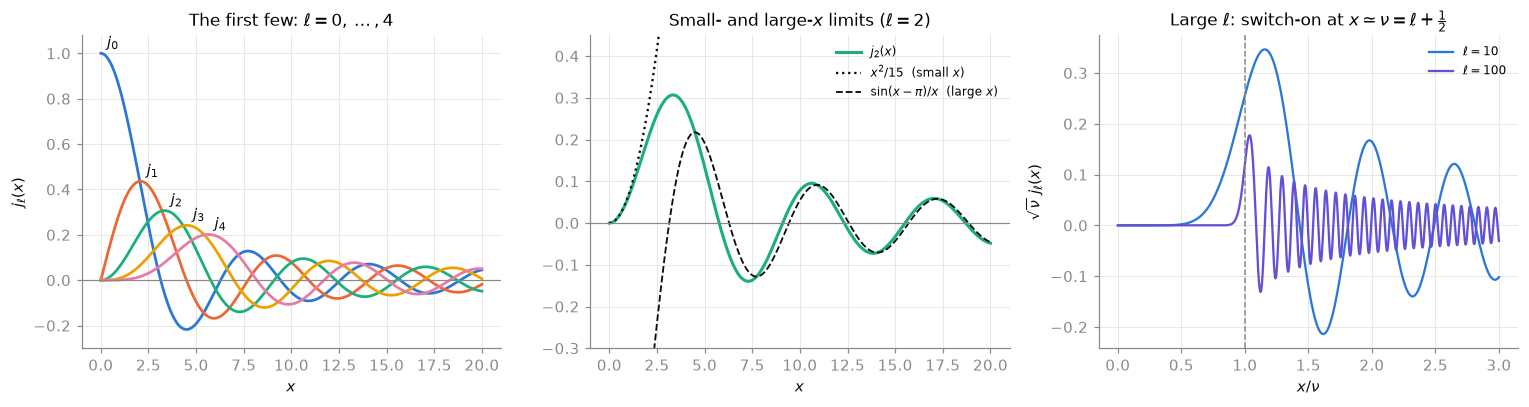

In [2]:
from scipy.special import factorial2

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

# (a) the first few j_ell
x = np.linspace(1e-3, 20, 2000)
for ell, col in zip(range(5), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]):
    y = spherical_jn(ell, x)
    ax[0].plot(x, y, color=col, lw=1.8)
    i = np.argmax(y)
    ax[0].annotate(fr"$j_{ell}$", (x[i], y[i]), xytext=(4, 4), textcoords="offset points", color=INK)
ax[0].axhline(0, color=MUTED, lw=0.8)
ax[0].set(xlabel="$x$", ylabel=r"$j_\ell(x)$", title=r"The first few: $\ell = 0,\dots,4$", ylim=(-0.3, 1.08))

# (b) j_2 and its two limits
ell = 2
ax[1].plot(x, spherical_jn(ell, x), color=C3, lw=2, label=r"$j_2(x)$")
ax[1].plot(x, x**ell / factorial2(2 * ell + 1), color=INK, lw=1.5, ls=":", label=r"$x^2/15$  (small $x$)")
ax[1].plot(x[x > 1], np.sin(x[x > 1] - ell * np.pi / 2) / x[x > 1], color=INK, lw=1.2, ls="--",
           label=r"$\sin(x-\pi)/x$  (large $x$)")
ax[1].axhline(0, color=MUTED, lw=0.8)
ax[1].set(xlabel="$x$", ylim=(-0.3, 0.45), title=r"Small- and large-$x$ limits ($\ell=2$)")
ax[1].legend(fontsize=8, loc="upper right")

# (c) large ell: the switch-on at x ~ nu
for ell, col in [(10, C1), (100, C4)]:
    nu = ell + 0.5
    xx = np.linspace(0.01, 3 * nu, 3000)
    ax[2].plot(xx / nu, spherical_jn(ell, xx) * np.sqrt(nu), color=col, lw=1.5, label=fr"$\ell={ell}$")
ax[2].axvline(1, color=MUTED, lw=1, ls="--")
ax[2].set(xlabel=r"$x/\nu$", ylabel=r"$\sqrt{\nu}\;j_\ell(x)$", title=r"Large $\ell$: switch-on at $x\simeq\nu=\ell+\frac{1}{2}$")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Setup: cosmology, $P(k)$, and two redshift distributions

In [3]:
# ---- Flat LCDM (Planck-2018-like) ----
h, Om, Ob, ns, sigma8 = 0.674, 0.315, 0.049, 0.965, 0.811
c_kms, H0 = 299792.458, 100 * h                      # distances in Mpc, k in 1/Mpc
E = lambda z: np.sqrt(Om * (1 + z)**3 + 1 - Om)

zg = np.linspace(0, 5, 5001)
chig = cumulative_trapezoid(c_kms / (H0 * E(zg)), zg, initial=0)
chi_of_z = interp1d(zg, chig, kind="cubic")

# Linear growth factor, D(z=0)=1:  D(a) ∝ H(a) ∫ da / (a H)^3
a_g = np.linspace(1e-3, 1, 400)
D_g = np.array([E(1/a - 1) * quad(lambda x: (x * E(1/x - 1))**-3, 0, a)[0] for a in a_g])
D_of_z = interp1d(1/a_g - 1, D_g / D_g[-1], kind="cubic")

# ---- Eisenstein & Hu (1998) no-wiggle transfer function ----
def T_EH(k):
    om, ob, fb, th = Om * h**2, Ob * h**2, Ob / Om, 2.7255 / 2.7
    s = 44.5 * np.log(9.83 / om) / np.sqrt(1 + 10 * ob**0.75)
    aG = 1 - 0.328 * np.log(431 * om) * fb + 0.38 * np.log(22.3 * om) * fb**2
    Gam = Om * h * (aG + (1 - aG) / (1 + (0.43 * k * s)**4))
    q = k * th**2 / (Gam * h)
    L0, C0 = np.log(2 * np.e + 1.8 * q), 14.2 + 731 / (1 + 62.5 * q)
    return L0 / (L0 + C0 * q**2)

def _sigma_R(R, A=1.0):
    k = np.logspace(-5, 2, 20000); x = k * R
    Wth = 3 * (np.sin(x) - x * np.cos(x)) / x**3
    return np.sqrt(np.trapezoid(k**2 * A * k**ns * T_EH(k)**2 * Wth**2, k) / (2 * np.pi**2))

A_s = (sigma8 / _sigma_R(8 / h))**2
P = lambda k: A_s * k**ns * T_EH(k)**2                 # linear P(k, z=0) in Mpc^3

# ---- Gaussian n(z) -> normalised W(chi) ----
def make_kernel(zc, sz, nsig, N=2000):
    z = np.linspace(max(zc - nsig * sz, 1e-3), zc + nsig * sz, N)
    chi = chi_of_z(z)
    W = np.exp(-0.5 * ((z - zc) / sz)**2) * H0 * E(z) / c_kms     # n(z) dz/dchi
    W /= np.trapezoid(W, chi)
    sig_chi = np.sqrt(np.trapezoid(W * chi**2, chi) - np.trapezoid(W * chi, chi)**2)
    return dict(z=z, chi=chi, W=W, D=D_of_z(z), sig_chi=sig_chi)

kernels = {
    "broad  (σ_z = 0.08)": make_kernel(0.5, 0.08, 4),   # photometric-like bin
    "narrow (σ_z = 0.01)": make_kernel(0.5, 0.01, 5),   # thin, spectroscopic-like slice
}
colors = {name: col for name, col in zip(kernels, [C1, C2])}
for name, K in kernels.items():
    print(f"{name}:  chi in [{K['chi'][0]:.0f}, {K['chi'][-1]:.0f}] Mpc,  sigma_chi = {K['sig_chi']:.0f} Mpc")

broad  (σ_z = 0.08):  chi in [766, 2929] Mpc,  sigma_chi = 269 Mpc
narrow (σ_z = 0.01):  chi in [1781, 2117] Mpc,  sigma_chi = 34 Mpc


### The two integrals in code

`cl_limber` is Eq. (3), a single `trapezoid` call. `cl_exact` is Eq. (1). To keep it reasonably fast, the grids are chosen per $\ell$:

* $k$ runs from just below $\nu/\chi_{\max}$ (where $j_\ell$ switches on) to $\nu/\chi_{\min} + 8/\sigma_\chi$. Beyond that, $I_\ell(k)$ is exponentially suppressed.
* Both grids use `ppo` points per oscillation: per period $2\pi/k_{\max}$ in $\chi$, and per period $2\pi/\chi_{\max}$ in $k$.
* $j_\ell(x)$ is only evaluated where it is not negligible, i.e. $x > \nu - 6\nu^{1/3}$.

Even with these tricks, the exact integral needs $10^5$–$10^6$ Bessel-function evaluations per multipole. Limber needs about $10^3$ evaluations of $P(k)$.

In [4]:
def cl_limber(ell, K, shift=0.5):
    nu = ell + shift
    return np.trapezoid(K["W"]**2 * K["D"]**2 / K["chi"]**2 * P(nu / K["chi"]), K["chi"])

def jl_masked(ell, X):
    # spherical Bessel j_ell, skipping the region x << nu where it is ~0
    nu, out = ell + 0.5, np.zeros_like(X)
    m = X > nu - 6 * nu**(1/3) - 2 if ell > 5 else np.ones_like(X, bool)
    out[m] = spherical_jn(ell, X[m])
    return out

def exact_grids(ell, K, ppo=8):
    nu, chi = ell + 0.5, K["chi"]
    kmin = max(nu - 6 * nu**(1/3) - 2, 0) / chi[-1]
    kmax = nu / chi[0] + 8 / K["sig_chi"]
    Nc = int(ppo * kmax * (chi[-1] - chi[0]) / (2 * np.pi)) + 50
    Nk = int(ppo * (kmax - kmin) * chi[-1] / (2 * np.pi)) + 50
    return np.linspace(max(kmin, 1e-6), kmax, Nk), np.linspace(chi[0], chi[-1], Nc)

def I_ell(ell, k, chi_f, K):
    WD = np.interp(chi_f, K["chi"], K["W"] * K["D"])
    return np.trapezoid(jl_masked(ell, np.outer(k, chi_f)) * WD, chi_f, axis=1)

def cl_exact(ell, K, ppo=8):
    k, chi_f = exact_grids(ell, K, ppo)
    return 2 / np.pi * np.trapezoid(k**2 * P(k) * I_ell(ell, k, chi_f, K)**2, k)

## 5. Ingredients

Left: the linear power spectrum. Right: the two radial weights. The narrow slice is $\sim 35$ Mpc wide, comparable to the scales on which $P(k)$ has structure; the broad bin is $\sim 270$ Mpc wide.

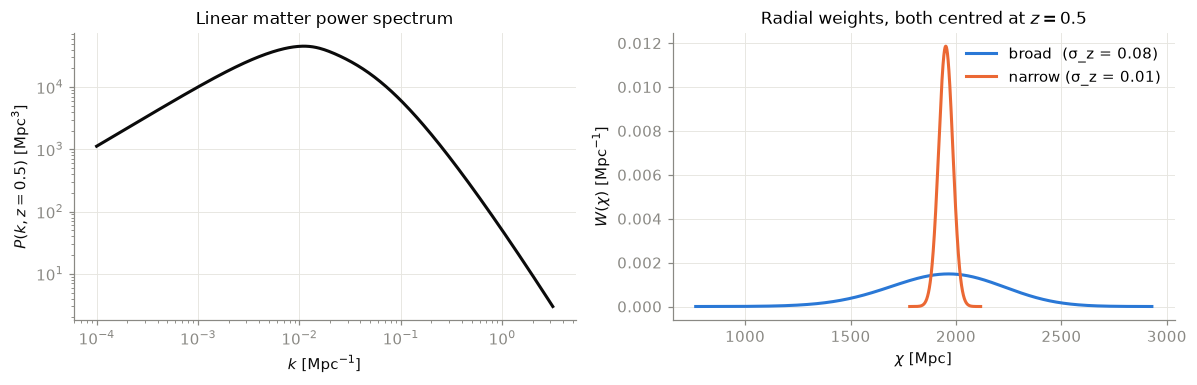

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

k = np.logspace(-4, 0.5, 400)
ax[0].loglog(k, P(k) * D_of_z(0.5)**2, color=INK)
ax[0].set(xlabel=r"$k$ [Mpc$^{-1}$]", ylabel=r"$P(k, z=0.5)$ [Mpc$^3$]", title="Linear matter power spectrum")

for name, K in kernels.items():
    ax[1].plot(K["chi"], K["W"], color=colors[name], label=name)
ax[1].set(xlabel=r"$\chi$ [Mpc]", ylabel=r"$W(\chi)$ [Mpc$^{-1}$]", title="Radial weights, both centred at $z=0.5$")
ax[1].legend()

plt.tight_layout(); plt.show()

## 6. The integrand of the exact $C_\ell$

Here is the inner integral $I_\ell(k)$ from Eq. (1), compared with its Limber form $\sqrt{\pi/2\nu}\;W(\nu/k)D/k$ (dashed) at $\ell=30$.

* **Broad kernel:** $I_\ell(k)$ is smooth and almost exactly the Limber curve. The oscillations of $j_\ell$ average out against a slowly varying $W$.
* **Narrow kernel:** $I_\ell(k)$ looks like $j_\ell(k\bar\chi)$ itself. It **oscillates in $k$** with period $2\pi/\bar\chi \approx 3\times10^{-3}$ Mpc$^{-1}$ and has a long tail that the Limber form does not have.

The bottom row shows the integrand of the outer $k$ integral, $\frac{2}{\pi}k^2P(k)I_\ell^2$. The area under each curve is $C_\ell$. For the narrow slice, Limber puts all the weight into a tall spike at $k=\nu/\bar\chi$. The exact integrand spreads it over a ringing tail, and the two areas differ by about 25% at this $\ell$.

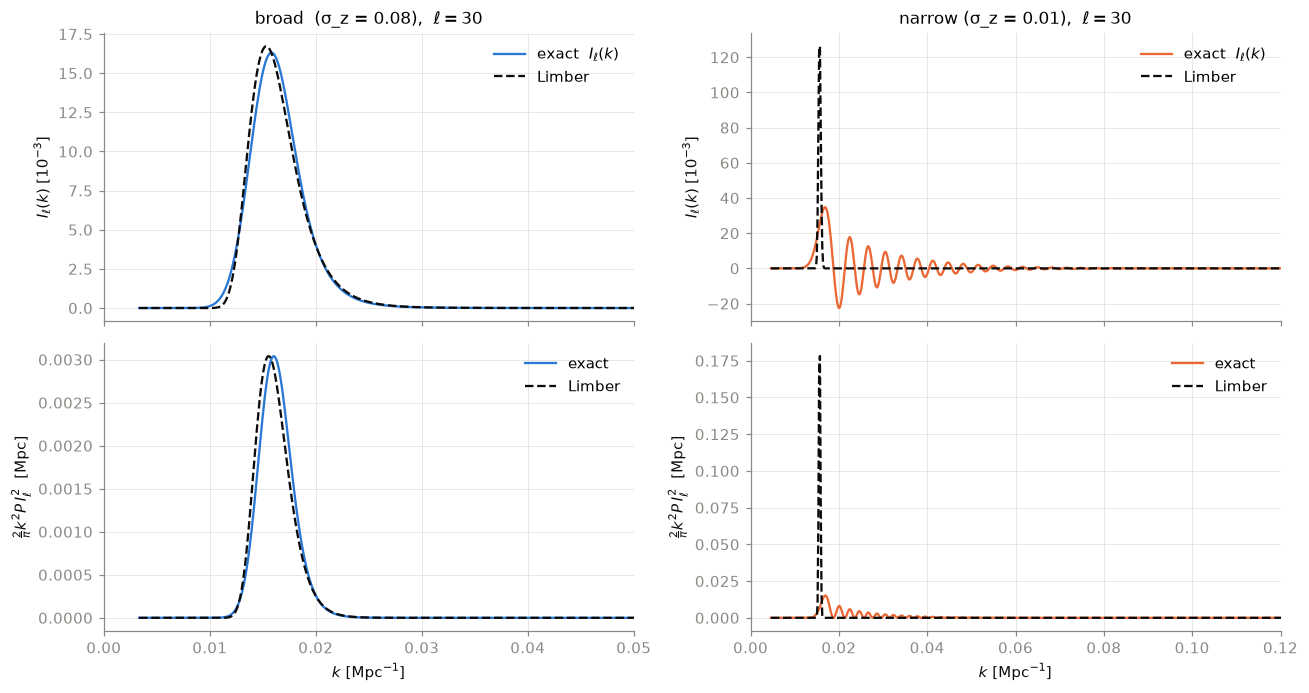

In [6]:
ell = 30; nu = ell + 0.5
fig, ax = plt.subplots(2, 2, figsize=(12, 6.4), sharex="col")
for j, (name, K) in enumerate(kernels.items()):
    k, chi_f = exact_grids(ell, K, ppo=16)
    I = I_ell(ell, k, chi_f, K)
    chi_k = nu / k
    WD_L = np.interp(chi_k, K["chi"], K["W"] * K["D"], left=0, right=0)
    I_L = np.sqrt(np.pi / (2 * nu)) * WD_L / k

    ax[0, j].plot(k, I * 1e3, color=colors[name], lw=1.5, label="exact  $I_\\ell(k)$")
    ax[0, j].plot(k, I_L * 1e3, color=INK, lw=1.5, ls="--", label="Limber")
    ax[0, j].set(ylabel=r"$I_\ell(k)\;[10^{-3}]$", title=f"{name},  $\\ell={ell}$")
    ax[0, j].legend()

    ax[1, j].plot(k, 2 / np.pi * k**2 * P(k) * I**2, color=colors[name], lw=1.5, label="exact")
    ax[1, j].plot(k, 2 / np.pi * k**2 * P(k) * I_L**2, color=INK, lw=1.5, ls="--", label="Limber")
    ax[1, j].set(xlabel=r"$k$ [Mpc$^{-1}$]", ylabel=r"$\frac{2}{\pi}k^2 P\, I_\ell^2$  [Mpc]")
    ax[1, j].legend()
ax[0, 0].set_xlim(0, 0.05); ax[0, 1].set_xlim(0, 0.12)
plt.tight_layout(); plt.show()

## 7. Why the exact integral converges slowly, and why that is Limber's argument

### A physical picture: correlations between shells

Swap the order of integration in Eq. (1):

$$
C_\ell = \int d\chi\,d\chi'\;W(\chi)D(\chi)\,W(\chi')D(\chi')\;\mathcal K_\ell(\chi,\chi'),
\qquad
\mathcal K_\ell(\chi,\chi') = \frac{2}{\pi}\int_0^{\infty} dk\,k^2 P(k)\,j_\ell(k\chi)\,j_\ell(k\chi').
\tag{4}
$$

Picture two thin spherical shells around the observer, at distances $\chi$ and $\chi'$. Expand the density on each shell in spherical harmonics, $\delta(\chi\hat{\mathbf n}) = \sum_{\ell m} a_{\ell m}(\chi)\,Y_{\ell m}(\hat{\mathbf n})$. Then $\mathcal K_\ell(\chi,\chi')$ is the covariance $\langle a_{\ell m}(\chi)\,a^*_{\ell m}(\chi')\rangle$, up to the growth factors. It measures how much the multipole-$\ell$ pattern on one shell resembles the pattern on the other. Eq. (4) says $C_\ell$ is these shell-to-shell correlations, summed with weights $W(\chi)W(\chi')$.

* Shells far apart compared with the correlation length of the density field are independent, so $\mathcal K_\ell \to 0$.
* So, as a function of the separation $\Delta = \chi' - \chi$, $\mathcal K_\ell$ is a **peak** centred on $\Delta = 0$.
* **Limber's approximation is the statement that this peak is a delta function**: $\mathcal K_\ell(\chi,\chi+\Delta) \approx \frac{P(\nu/\chi)}{\chi^2}\,\delta_D(\Delta)$. Put this into Eq. (4) and you get Eq. (3).

Below we fix $\chi = 1950$ Mpc (the centre of both redshift distributions) and plot the kernel in normalised form,

$$
\tilde{\mathcal{K}}_\ell(\Delta) \equiv \frac{\chi^2\,\mathcal K_\ell(\chi,\chi+\Delta)}{P(\nu/\chi)} \;\xrightarrow{\ \rm Limber\ }\; \delta_D(\Delta),
$$

so that Limber corresponds to a spike of **unit area**.

### 7a. Even one value of the kernel converges slowly

* **Left and middle:** the integrand of $\mathcal K_\ell$ in Eq. (4), at $\ell = 100$. It oscillates very quickly in $k$ (period $\approx\pi/\chi$), so at this scale it appears as a filled band.
  * For the **same shell** ($\Delta = 0$) it is $\propto j_\ell^2 \ge 0$, so every bit adds up.
  * For shells **50 Mpc apart**, $j_\ell(k\chi)$ and $j_\ell(k\chi')$ drift in and out of phase with a beat period $2\pi/\Delta \approx 0.13$ Mpc$^{-1}$. The integrand flips sign, and positive and negative lobes almost cancel.
* **Right:** the running integral up to $k_{\max}$. For $\Delta = 0$ it climbs steadily. For $\Delta \neq 0$ it overshoots and then oscillates around its final value. The wiggles die out only as fast as $P(k)$ decays, so they settle only at $k_{\max} \sim 1$ Mpc$^{-1}$, twenty times beyond the $k=\nu/\chi$ that Limber picks out. A brute-force calculation has to do this for every pair of shells and every $\ell$.

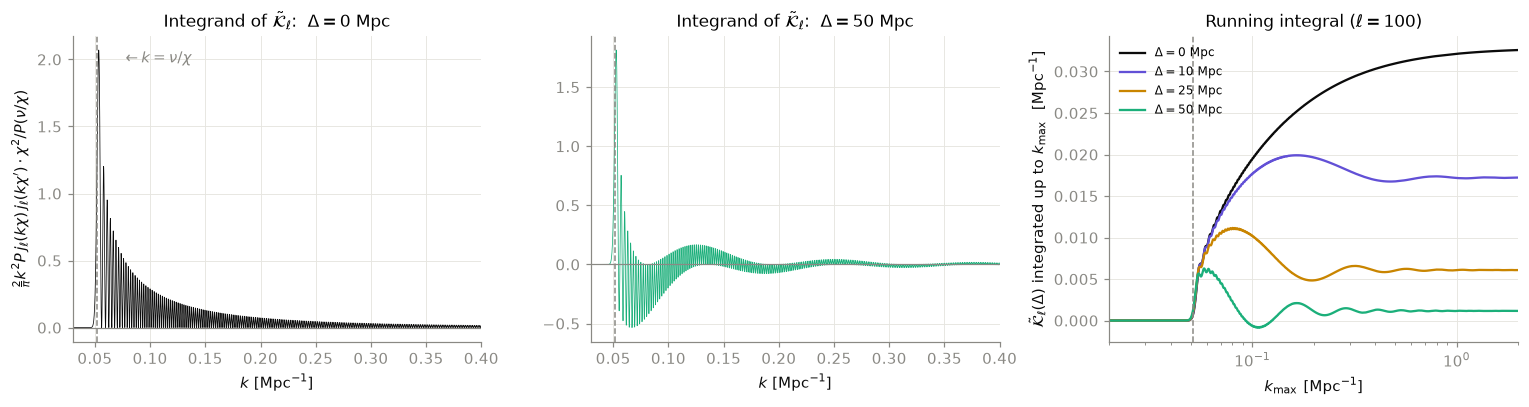

In [7]:
ell, chi0 = 100, 1950.0; nu = ell + 0.5
D2 = D_of_z(0.5)**2
k = np.linspace(1e-4, 2.0, 40000)
# integrand of K~_ell, already normalised by chi^2 / (D^2 P(nu/chi))
base = 2 / np.pi * k**2 * P(k) * spherical_jn(ell, k * chi0) * chi0**2 / P(nu / chi0)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, dlt, col in [(ax[0], 0, INK), (ax[1], 50, C3)]:
    a.plot(k, base * spherical_jn(ell, k * (chi0 + dlt)), color=col, lw=0.5)
    a.axhline(0, color=MUTED, lw=0.8)
    a.axvline(nu / chi0, color=MUTED, ls="--", lw=1)
    a.set(xlim=(0.03, 0.4), xlabel=r"$k$ [Mpc$^{-1}$]", title=fr"Integrand of $\tilde{{\mathcal{{K}}}}_\ell$:  $\Delta = {dlt}$ Mpc")
ax[0].set_ylabel(r"$\frac{2}{\pi}k^2P\,j_\ell(k\chi)\,j_\ell(k\chi')\cdot\chi^2/P(\nu/\chi)$")
ax[0].text(0.075, 0.95 * ax[0].get_ylim()[1], r"$\leftarrow k=\nu/\chi$", color=MUTED, va="top")

for dlt, col in zip([0, 10, 25, 50], [INK, C4, "#c98500", C3]):
    cum = cumulative_trapezoid(base * spherical_jn(ell, k * (chi0 + dlt)), k, initial=0)
    ax[2].plot(k, cum, color=col, lw=1.5, label=fr"$\Delta = {dlt}$ Mpc")
ax[2].axvline(nu / chi0, color=MUTED, ls="--", lw=1)
ax[2].set(xscale="log", xlim=(2e-2, 2), xlabel=r"$k_{\max}$ [Mpc$^{-1}$]",
          ylabel=r"$\tilde{\mathcal{K}}_\ell(\Delta)$ integrated up to $k_{\max}$  [Mpc$^{-1}$]",
          title=fr"Running integral ($\ell={ell}$)")
ax[2].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### 7b. The converged kernel, and the Limber criterion

**Top:** the converged kernel $\tilde{\mathcal{K}}_\ell(\Delta)$ for three multipoles. Each has area $\approx 1$ (printed below), just as Limber assumes. But it is a peak of finite width, not a spike. All three have a sharp core, about 20 Mpc across, set by small-scale correlations. They differ in their **wings**. At $\ell = 100$ the kernel is compact. At lower $\ell$ it develops broad wings reaching $\sim$100–200 Mpc, because the dominant modes have $k\approx\nu/\chi$, i.e. long wavelengths that stay correlated over large radial distances. At $\ell = 10$ the wings even go slightly negative beyond $|\Delta|\sim150$ Mpc: shells that far apart are weakly anti-correlated at that multipole.

**Bottom:** the two redshift weights around the same point, $W(\chi+\Delta)/W(\chi)$.

**Reading the two panels together.** At shell $\chi$, Eq. (4) needs the kernel *averaged over the weight*, $\int d\Delta\;\tilde{\mathcal{K}}_\ell(\Delta)\,W(\chi+\Delta)$. Limber replaces this by $W(\chi)\int d\Delta\,\tilde{\mathcal{K}}_\ell = W(\chi)$. The ratio

$$
R_\ell = \int d\Delta\;\tilde{\mathcal{K}}_\ell(\Delta)\;\frac{W(\chi+\Delta)}{W(\chi)}
$$

is therefore "exact ÷ Limber" for that shell, and **Limber works when $R_\ell \approx 1$, i.e. when $W$ is flat across the width of the kernel**:

* The **broad** weight (blue) is almost flat across all three kernels, so $R_\ell\approx1$. The exception is $\ell = 10$, whose wide wings start to feel the curvature of $W$.
* The **narrow** weight (orange) is about as wide as the kernels' wings. It cuts off part of each peak, so $R_\ell < 1$ and Limber **over-predicts** at the centre of the slice.

The table printed below gives $R_\ell$ at the centre. That is one shell, not the full answer. In the *wings* of $W$ the opposite happens: the kernel reaches towards the denser centre, so $R_\ell > 1$ there. The $C_\ell$ errors in Section 8 are a weighted average over all shells. They have the sign of the central $R_\ell$ but are smaller: about $+25\%$ and $+8\%$ for the narrow slice at $\ell = 30$ and $100$. At $\ell = 10$ the centre and the wings almost cancel, which is why the narrow-slice $C_\ell$ happens to cross Limber there.

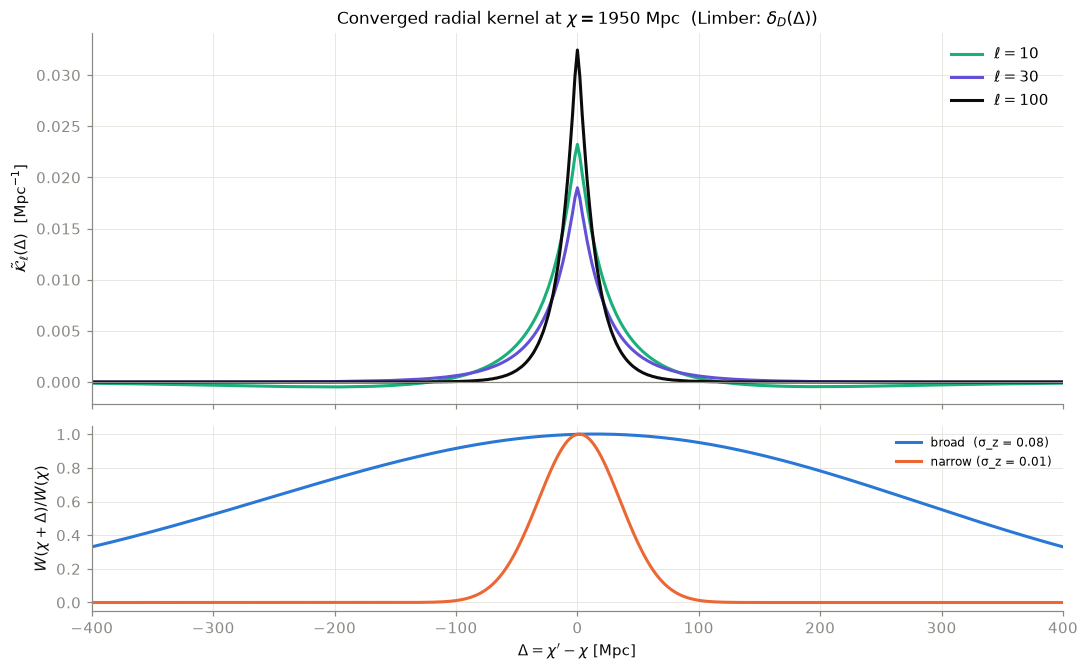

 ell    area  R_ell broad  R_ell narrow     (Limber assumes 1)
  10   1.028        1.078         0.891
  30   1.000        0.988         0.709
 100   1.000        0.997         0.868


In [8]:
k = np.linspace(1e-4, 1.5, 20000)
d = np.arange(-400, 401, 2.0)
fig, ax = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
rows = []
for ell, col in [(10, C3), (30, C4), (100, INK)]:      # not blue/orange: those mean broad/narrow below
    nu = ell + 0.5
    base = 2 / np.pi * k**2 * P(k) * spherical_jn(ell, k * chi0) * chi0**2 / P(nu / chi0)
    Kt = np.trapezoid(base[:, None] * jl_masked(ell, np.outer(k, chi0 + d)), k, axis=0)
    ax[0].plot(d, Kt, color=col, lw=2, label=fr"$\ell = {ell}$")
    R = {}
    for name, K in kernels.items():
        WD = K["W"] * K["D"]
        ratio = np.interp(chi0 + d, K["chi"], WD, left=0, right=0) / np.interp(chi0, K["chi"], WD)
        R[name] = np.trapezoid(Kt * ratio, d)
    rows.append((ell, np.trapezoid(Kt, d), *R.values()))
ax[0].axhline(0, color=MUTED, lw=0.8)
ax[0].set(ylabel=r"$\tilde{\mathcal{K}}_\ell(\Delta)$  [Mpc$^{-1}$]", title=r"Converged radial kernel at $\chi = 1950$ Mpc  (Limber: $\delta_D(\Delta)$)")
ax[0].legend()

for name, K in kernels.items():
    ax[1].plot(d, np.interp(chi0 + d, K["chi"], K["W"], left=0, right=0) / np.interp(chi0, K["chi"], K["W"]),
               color=colors[name], lw=2, label=name)
ax[1].set(xlabel=r"$\Delta = \chi' - \chi$ [Mpc]", ylabel=r"$W(\chi+\Delta)/W(\chi)$", xlim=(-400, 400))
ax[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

names = list(kernels)
print(f"{'ell':>4} {'area':>7} {'R_ell broad':>12} {'R_ell narrow':>13}     (Limber assumes 1)")
for ell, area, rb, rn in rows:
    print(f"{ell:>4} {area:7.3f} {rb:12.3f} {rn:13.3f}")

### 7c. Brute force: cost and convergence

What does it cost to get $C_\ell$ right with a straightforward grid? Below, both integrals in Eq. (1) use the **same simple uniform grid** of $N$ points in $k\in[10^{-4}, 1]$ Mpc$^{-1}$ and in $\chi$ across the kernel. We plot the relative error against a converged reference. Limber (Eq. 3) uses $N$ points in $\chi$ and is compared with its own converged value.

The exact integral returns noise, with errors of order unity, until the grid resolves the oscillations. That takes $\Delta k \lesssim 2\pi/\chi$ and $\Delta\chi\lesssim 2\pi/k_{\max}$, i.e. several hundred points per dimension here, however smooth the final $C_\ell$ is. Convergence is erratic rather than steady: aliasing can make a coarse grid look accurate by luck (the dips). The cost is $N^2$ Bessel evaluations per multipole, and each evaluation gets more expensive as $\ell$ grows (right). Limber reaches $10^{-6}$ with a few dozen points of a smooth integrand.

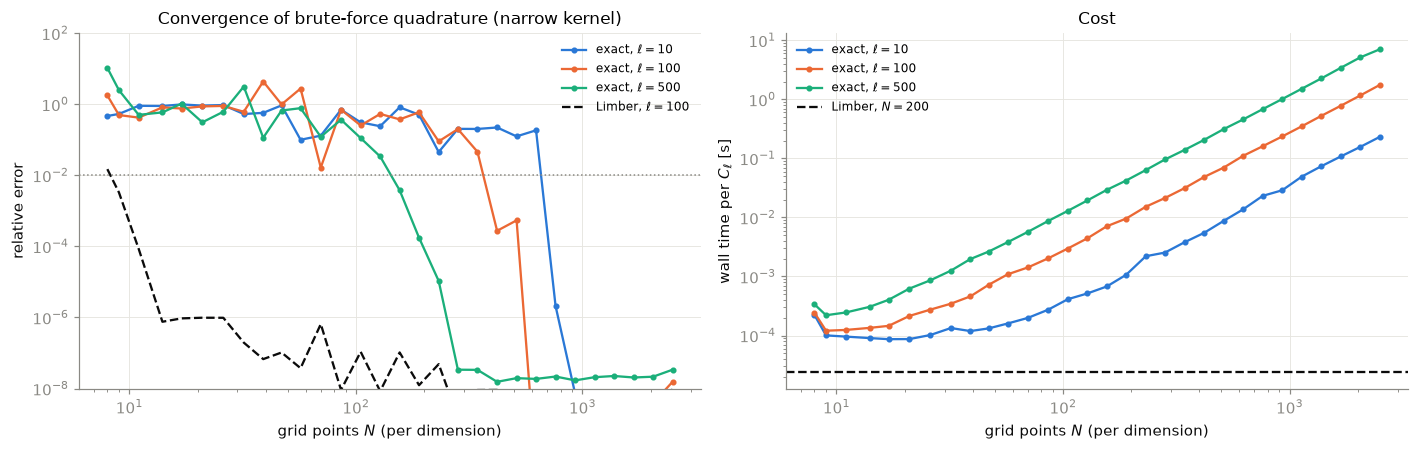

In [9]:
def cl_exact_uniform(ell, K, N):
    k = np.linspace(1e-4, 1.0, N)
    chi_f = np.linspace(K["chi"][0], K["chi"][-1], N)
    return 2 / np.pi * np.trapezoid(k**2 * P(k) * I_ell(ell, k, chi_f, K)**2, k)

def cl_limber_N(ell, K, N):
    chi = np.linspace(K["chi"][0], K["chi"][-1], N)
    WD = np.interp(chi, K["chi"], K["W"] * K["D"])
    return np.trapezoid(WD**2 / chi**2 * P((ell + 0.5) / chi), chi)

Ns = np.unique(np.geomspace(8, 2500, 30).astype(int))
K = kernels["narrow (σ_z = 0.01)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for ell, col in [(10, C1), (100, C2), (500, C3)]:
    ref = cl_exact(ell, K, ppo=16)
    err, t = [], []
    for N in Ns:
        t0 = time.perf_counter(); v = cl_exact_uniform(ell, K, N); t.append(time.perf_counter() - t0)
        err.append(abs(v / ref - 1))
    ax[0].loglog(Ns, np.maximum(err, 1e-16), color=col, marker="o", ms=3, lw=1.5, label=fr"exact, $\ell={ell}$")
    ax[1].loglog(Ns, t, color=col, marker="o", ms=3, lw=1.5, label=fr"exact, $\ell={ell}$")
refL = cl_limber_N(100, K, 20000)
errL = [abs(cl_limber_N(100, K, N) / refL - 1) for N in Ns]
ax[0].loglog(Ns, np.maximum(errL, 1e-16), color=INK, ls="--", lw=1.5, label=r"Limber, $\ell=100$")
ax[0].axhline(1e-2, color=MUTED, lw=1, ls=":")
ax[0].set(xlabel="grid points $N$ (per dimension)", ylabel="relative error", ylim=(1e-8, 1e2),
          title="Convergence of brute-force quadrature (narrow kernel)")
ax[0].legend(fontsize=8)
t0 = time.perf_counter()
for _ in range(100): cl_limber_N(100, K, 200)
ax[1].axhline((time.perf_counter() - t0) / 100, color=INK, ls="--", lw=1.5, label="Limber, $N=200$")
ax[1].set(xlabel="grid points $N$ (per dimension)", ylabel="wall time per $C_\\ell$ [s]", title="Cost")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Exact vs. Limber: the angular power spectrum

Now the main result. We compute the exact $C_\ell$ (Eq. 1) on a log-spaced set of multipoles and compare it with Limber (Eq. 3) using $k=(\ell+\frac12)/\chi$ (solid) and $k=\ell/\chi$ (dotted).

In [10]:
ells_ex = np.unique(np.geomspace(2, 1000, 40).astype(int))
ells_L = np.arange(2, 10001)          # Limber is cheap: go high so w(theta) below is well resolved
res = {}
for name, K in kernels.items():
    t0 = time.perf_counter()
    ce = np.array([cl_exact(l, K) for l in ells_ex])
    t_ex = time.perf_counter() - t0
    t0 = time.perf_counter()
    cL = np.array([cl_limber(l, K) for l in ells_L])
    t_L = time.perf_counter() - t0
    cL0 = np.array([cl_limber(l, K, shift=0.0) for l in ells_L])
    res[name] = dict(exact=ce, limber=cL, limber0=cL0)
    print(f"{name}:  exact {len(ells_ex)} multipoles in {t_ex:6.1f} s   |   Limber {len(ells_L)} multipoles in {t_L:5.2f} s")

broad  (σ_z = 0.08):  exact 37 multipoles in   89.6 s   |   Limber 9999 multipoles in  0.51 s


narrow (σ_z = 0.01):  exact 37 multipoles in    4.6 s   |   Limber 9999 multipoles in  0.51 s


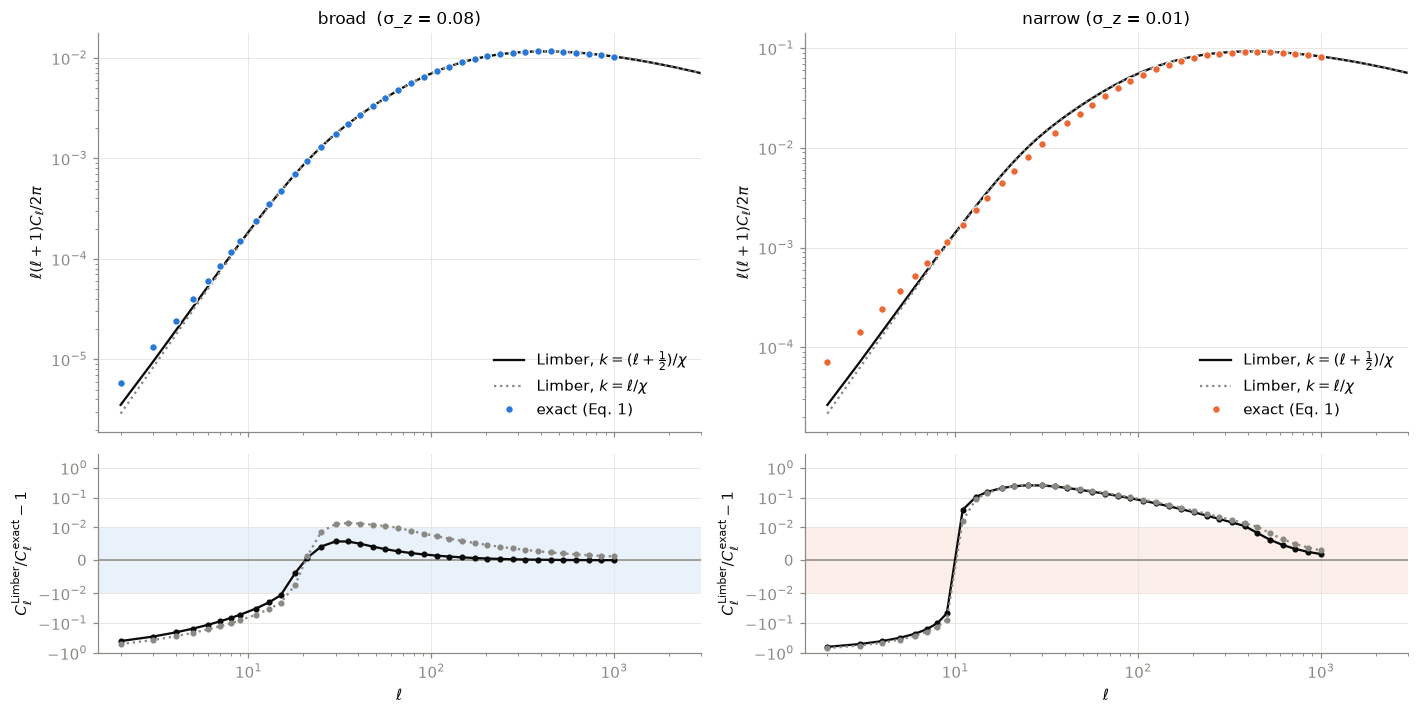

broad  (σ_z = 0.08): Limber (ℓ+½) error > 1% up to ℓ = 15
narrow (σ_z = 0.01): Limber (ℓ+½) error > 1% up to ℓ = 384


In [11]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6.6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for j, (name, r) in enumerate(res.items()):
    col = colors[name]
    a, b = ax[0, j], ax[1, j]
    a.loglog(ells_L, ells_L * (ells_L + 1) * r["limber"] / (2 * np.pi), color=INK, lw=1.5, label=r"Limber, $k=(\ell+\frac{1}{2})/\chi$")
    a.loglog(ells_L, ells_L * (ells_L + 1) * r["limber0"] / (2 * np.pi), color=MUTED, lw=1.5, ls=":", label=r"Limber, $k=\ell/\chi$")
    a.loglog(ells_ex, ells_ex * (ells_ex + 1) * r["exact"] / (2 * np.pi), "o", color=col, ms=5,
             markeredgecolor="white", markeredgewidth=0.8, label="exact (Eq. 1)")
    a.set(ylabel=r"$\ell(\ell+1)C_\ell/2\pi$", title=name)
    a.legend(loc="lower right")

    rL = np.interp(ells_ex, ells_L, r["limber"]) / r["exact"] - 1
    rL0 = np.interp(ells_ex, ells_L, r["limber0"]) / r["exact"] - 1
    b.axhspan(-0.01, 0.01, color=col, alpha=0.10, lw=0)
    b.axhline(0, color=MUTED, lw=1)
    b.plot(ells_ex, rL, color=INK, marker="o", ms=3, lw=1.5)
    b.plot(ells_ex, rL0, color=MUTED, marker="o", ms=3, lw=1.5, ls=":")
    b.set_yscale("symlog", linthresh=1e-2)
    b.set(xscale="log", xlim=(1.5, 3000), ylim=(-1, 3), xlabel=r"$\ell$", ylabel=r"$C_\ell^{\rm Limber}/C_\ell^{\rm exact} - 1$")
plt.tight_layout(); plt.show()

for name, r in res.items():
    rel = np.abs(np.interp(ells_ex, ells_L, r["limber"]) / r["exact"] - 1)
    bad = ells_ex[rel > 0.01]
    print(f"{name}: Limber (ℓ+½) error > 1% up to ℓ = {bad.max() if bad.size else '-'}")

**What we see**

* **Broad bin** (left): Limber with $\nu=\ell+\frac12$ is accurate to better than 1% above $\ell\sim\mathcal O(10)$. Only the lowest multipoles are off, and there Limber *under*-predicts power. This is the regime of Lemos et al. (2017): for broad weak-lensing kernels, the Limber and flat-sky approximations have *"negligible impact except at multipoles $\ell\lesssim10$."*
* **Narrow slice** (right): the radial kernel $\mathcal K_\ell$ is no longer narrow compared with $W$. Limber **over-predicts** $C_\ell$ by tens of percent at $\ell\sim30$, and the error falls below 1% only at $\ell$ of several hundred. This is Simon's (2007) point that Limber's $1/\sigma$ amplitude blows up for thin shells, while the true signal stays finite. (Limber happens to cross the exact curve near $\ell\approx10$ for the narrow slice. That is a coincidence, not a sign of accuracy.)
* The **$\ell$ vs. $\ell+\frac12$** choice matters at the per-cent level up to $\ell\sim100$ even for the broad bin. With $\nu=\ell+\frac12$ the error falls off like $\nu^{-2}$, as LoVerde & Afshordi (2008) predict, rather than like $1/\ell$.

## 9. Real space: $w(\theta)$ (the view of Simon 2007)

Simon (2007) works with the angular correlation function and writes the exact projection as a double integral over the 3D correlation function, $w(\theta) = \int dr_1\,dr_2\,p(r_1)p(r_2)\,\xi(R)$ with $R^2 = r_1^2 + r_2^2 - 2r_1r_2\cos\theta$ (his Eqs. 10–12). Limber replaces this with $\int d\bar r\,p^2(\bar r)\int d\Delta r\;\xi\big(\sqrt{\bar r^2\theta^2+\Delta r^2}\big)$ (his Eqs. 13–14). His conclusion: Limber is good at small $\theta$ and breaks down beyond an angle set mainly by $\sigma/\bar r$. As a rule of thumb, the error reaches 10% at $\theta\approx 260\,(\sigma/\bar r)$ arcmin for a power-law $\xi$ with $\gamma\approx1.6$.

We get the same physics by Legendre-transforming our two $C_\ell$'s,

$$
w(\theta) = \sum_\ell \frac{2\ell+1}{4\pi}\,C_\ell\,P_\ell(\cos\theta),
$$

using the exact $C_\ell$ where we have it (interpolating the smooth ratio exact/Limber in $\ln\ell$) and Limber above $\ell=1000$, where the two agree.

broad  (σ_z = 0.08): w(theta) crosses zero at 4.4 deg;  |Limber error| > 10% from theta = 3.32 deg
narrow (σ_z = 0.01): w(theta) crosses zero at 5.1 deg;  |Limber error| > 10% from theta = 0.37 deg


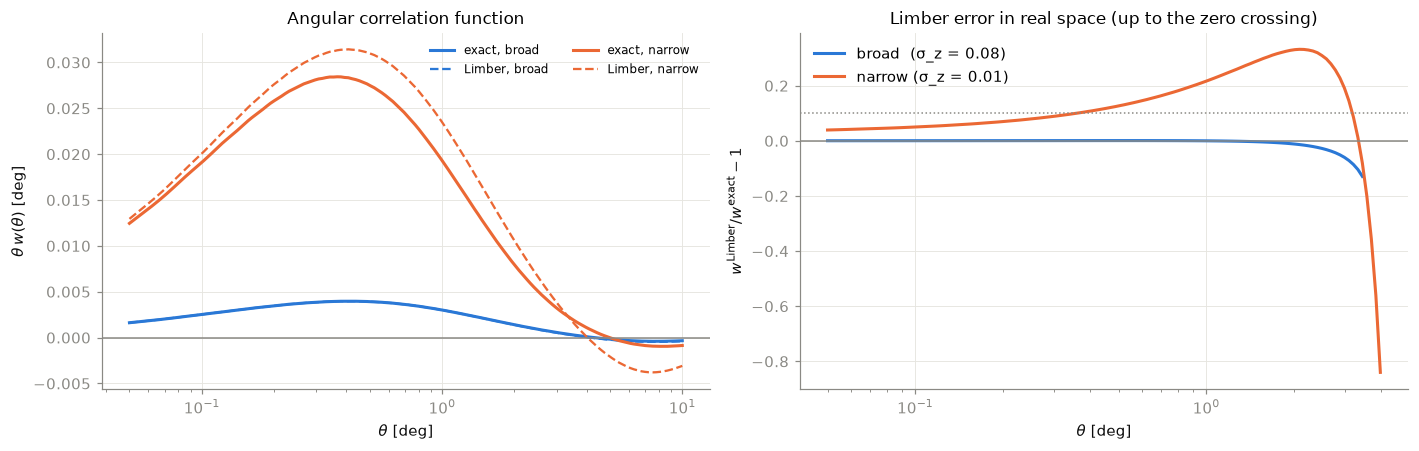

In [12]:
theta_deg = np.geomspace(0.05, 10, 150)
mu = np.cos(np.radians(theta_deg))
Pl = np.array([eval_legendre(l, mu) for l in ells_L])           # (n_ell, n_theta)
pref = (2 * ells_L + 1) / (4 * np.pi)                           # both curves start at l=2 (no monopole/dipole)

def exact_full(r):
    # exact C_l on all ells_L: interpolate exact/Limber in ln(l); above the last exact l,
    # let the residual decay like nu^-2 (LoVerde & Afshordi 2008)
    q = r["exact"] / np.interp(ells_ex, ells_L, r["limber"]) - 1
    resid = np.interp(np.log(ells_L), np.log(ells_ex), q)
    hi = ells_L > ells_ex[-1]
    resid[hi] = q[-1] * ((ells_ex[-1] + 0.5) / (ells_L[hi] + 0.5))**2
    return r["limber"] * (1 + resid)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, r in res.items():
    col, short = colors[name], name.split()[0]
    w_ex = (pref * exact_full(r)) @ Pl
    w_L = (pref * r["limber"]) @ Pl
    ax[0].plot(theta_deg, theta_deg * w_ex, color=col, lw=2, label=f"exact, {short}")
    ax[0].plot(theta_deg, theta_deg * w_L, color=col, lw=1.5, ls="--", label=f"Limber, {short}")
    th0 = theta_deg[np.argmax(w_ex < 0)]
    pos = theta_deg < 0.8 * th0                                  # stay clear of the zero crossing
    rel = w_L / w_ex - 1
    ax[1].plot(theta_deg[pos], rel[pos], color=col, lw=2, label=name)
    big = np.abs(rel[pos]) > 0.1
    th10 = f"{theta_deg[pos][np.argmax(big)]:.2f} deg" if big.any() else "never (before the zero crossing)"
    print(f"{name}: w(theta) crosses zero at {th0:.1f} deg;  |Limber error| > 10% from theta = {th10}")
ax[0].axhline(0, color=MUTED, lw=1)
ax[0].set(xscale="log", xlabel=r"$\theta$ [deg]", ylabel=r"$\theta\,w(\theta)$ [deg]", title="Angular correlation function")
ax[0].legend(ncol=2, fontsize=8)
ax[1].axhline(0, color=MUTED, lw=1)
ax[1].axhline(0.1, color=MUTED, lw=1, ls=":")
ax[1].set(xscale="log", xlabel=r"$\theta$ [deg]", ylabel=r"$w^{\rm Limber}/w^{\rm exact}-1$",
          title="Limber error in real space (up to the zero crossing)")
ax[1].legend()
plt.tight_layout(); plt.show()

The real-space picture matches Simon (2007). For the narrow slice, the Limber error **grows with angle** and blows up as $w(\theta)$ approaches its zero crossing. This is the real-space image of the low-$\ell$ failure above. The broad bin stays at the sub-per-cent level until the largest scales.

Two remarks:

* Even at the smallest angles, the narrow slice keeps an error of a few per cent. At $\theta\to0$, the exact result is $\int\!\!\int dr_1\,dr_2\,p(r_1)p(r_2)\,\xi(|r_1-r_2|)$, while Limber gives $\int dr\,p^2(r)\int d\Delta\,\xi(\Delta)$. These agree only if $p$ is flat over the range of $\xi$. The *linear* $\xi(r)$ used here has a lot of weight at tens of Mpc, comparable to the slice width. A steeper, nonlinear small-scale $\xi$ would make the small-angle agreement better.
* Simon's rule of thumb (10% error at $\approx 260\,\sigma/\bar r$ arcmin, $\approx 4.5'$ for our slice) was derived for a pure power-law $\xi\propto r^{-\gamma}$. Linear $\Lambda$CDM is far from a power law: it turns over and goes negative near 130 Mpc. So we should not expect the number to carry over, only the trend. Limber fails at smaller angles as $\sigma/\bar r$ shrinks.

## Take-aways

* The exact projection, Eq. (1), is an oscillatory double integral. A brute-force grid gives garbage until it resolves the Bessel oscillations, and the cost grows with $\ell$.
* The same oscillations make the radial kernel $\mathcal K_\ell(\chi,\chi')$ collapse to a narrow, unit-area peak. Limber, Eq. (3), is exactly the statement that $W(\chi)$ is flat across that peak.
* Use $k=(\ell+\frac12)/\chi$.
* Limber is excellent for broad kernels (weak lensing, wide photo-$z$ bins) above $\ell\sim10$–$20$ (Lemos et al. 2017). It is poor for narrow kernels at low $\ell$ / large $\theta$ (Simon 2007), which matters for thin tomographic slices, spectroscopic clustering, and cross-correlations of narrow bins.
* For that regime there are fast "beyond-Limber" methods, e.g. FFTLog-based approaches (Assassi et al. 2017; Fang et al. 2020).

## References

1. Limber, D. N. (1953), *The analysis of counts of the extragalactic nebulae in terms of a fluctuating density field*, ApJ **117**, 134.
2. Kaiser, N. (1992), *Weak gravitational lensing of distant galaxies*, ApJ **388**, 272.
3. **Simon, P.** (2007), *How accurate is Limber's equation?*, A&A **473**, 711. arXiv:[astro-ph/0609165](https://arxiv.org/abs/astro-ph/0609165).
4. LoVerde, M. & Afshordi, N. (2008), *Extended Limber approximation*, Phys. Rev. D **78**, 123506. arXiv:[0809.5112](https://arxiv.org/abs/0809.5112).
5. **Lemos, P., Challinor, A. & Efstathiou, G.** (2017), *The effect of Limber and flat-sky approximations on galaxy weak lensing*, JCAP **05**, 014. arXiv:[1704.01054](https://arxiv.org/abs/1704.01054).
6. Eisenstein, D. J. & Hu, W. (1998), *Baryonic features in the matter transfer function*, ApJ **496**, 605. arXiv:[astro-ph/9709112](https://arxiv.org/abs/astro-ph/9709112).
7. Assassi, V., Simonović, M. & Zaldarriaga, M. (2017), *Efficient evaluation of angular power spectra and bispectra*, JCAP **11**, 054. arXiv:[1705.05022](https://arxiv.org/abs/1705.05022).
8. Fang, X., Krause, E., Eifler, T. & MacCrann, N. (2020), *Beyond Limber: efficient computation of angular power spectra for galaxy clustering and weak lensing*, JCAP **05**, 010. arXiv:[1911.11947](https://arxiv.org/abs/1911.11947).
9. Planck Collaboration (2020), *Planck 2018 results. VI. Cosmological parameters*, A&A **641**, A6. arXiv:[1807.06209](https://arxiv.org/abs/1807.06209). (Cosmological parameters used here.)